In [1]:
# conda env 'at3d_pure'

import sys
sys.path.append('/data/keeling/a/johntl3/b/LundstromPub2025/src')

import xarray as xr
import numpy as np
from util import load_sensor_dict
import at3d
import matplotlib.pyplot as plt

In [3]:
file1D = './OBS_1DRT.nc'
file3D = './OBS_3DRT.nc'

sensor1D = load_sensor_dict(file1D)
sensor3D = load_sensor_dict(file3D)

In [8]:
sensor1D['MISR']['sensor_list'][0]

<xarray.Dataset>
Dimensions:            (stokes_index: 4, npixels: 4225, bbox: 6, image_dims: 2,
                        nrays: 4225)
Coordinates:
  * stokes_index       (stokes_index) object 'I' 'Q' 'U' 'V'
  * bbox               (bbox) object 'xmin' 'ymin' 'zmin' 'xmax' 'ymax' 'zmax'
  * image_dims         (image_dims) object 'nx' 'ny'
Dimensions without coordinates: npixels, nrays
Data variables: (12/18)
    wavelength         float64 0.67
    stokes             (stokes_index) bool True False False False
    cam_x              (npixels) float64 0.0 0.275 0.55 ... 17.05 17.33 17.6
    cam_y              (npixels) float64 0.0 0.0 0.0 0.0 ... 17.6 17.6 17.6 17.6
    cam_z              (npixels) float64 1.4 1.4 1.4 1.4 1.4 ... 1.4 1.4 1.4 1.4
    cam_mu             (npixels) float64 1.0 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0 1.0
    ...                 ...
    ray_y              (nrays) float64 0.0 0.0 0.0 0.0 ... 17.6 17.6 17.6 17.6
    ray_z              (nrays) float64 1.4 1.4 1.4 1.4 1.4 ... 1.4 1.4 1.4 1.4
    pixel_index        (nrays) int64 0 1 2 3 4 5 ... 4220 4221 4222 4223 4224
    ray_weight         (nrays) float64 1.0 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0 1.0
    use_subpixel_rays  bool False
    I                  (npixels) float64 0.0409 0.0409 0.0409 ... 0.0409 0.0409
Attributes:
    projection:          Orthographic
    altitude:            1.4
    x_resolution:        0.275
    y_resolution:        0.275
    projection_azimuth:  0
    projection_zenith:   0
    mu0:                 0.8776406058774511
    SAA:                 129.49041285289678

In [16]:
I1D = np.reshape(sensor1D['MISR']['sensor_list'][0].I.data, (65, 65))
I3D = np.reshape(sensor3D['MISR']['sensor_list'][0].I.data, (65, 65))

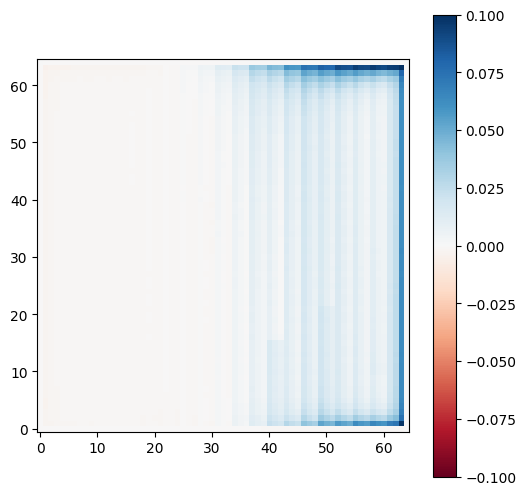

In [20]:
f, ax = plt.subplots(1, 1, figsize = (6, 6))
diff_ax = ax.imshow(I1D - I3D, origin = 'lower', cmap='RdBu', vmin=-0.1, vmax=0.1)
plt.colorbar(diff_ax)

In [2]:
lut1 = xr.load_dataset('./LUT_1DRT_taus1.nc')
lut2 = xr.load_dataset('./LUT_1DRT_taus2.nc')

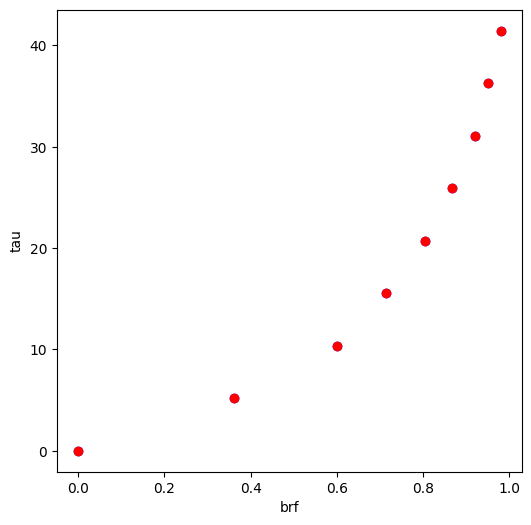

In [6]:
f, ax = plt.subplots(1, 1, figsize = (6, 6))
lut1.tau.plot(marker='o', linestyle='None', color='blue', label='tau1', ax=ax)
lut2.tau.plot(marker='o', linestyle='None', color='red', label='tau2', ax=ax)

In [17]:
lut1.sortby('tau').brf.data

array([4.61749237e-05, 3.62222907e-01, 6.01340699e-01, 7.14123771e-01,
       8.03645308e-01, 8.67779016e-01, 9.19289965e-01, 9.50025986e-01,
       9.80003297e-01])

In [18]:
lut2.sortby('tau').brf.data

array([4.61749237e-05, 3.62222934e-01, 6.01340646e-01, 7.14123344e-01,
       8.03644881e-01, 8.67777576e-01, 9.19289112e-01, 9.50024386e-01,
       9.80001911e-01])

In [19]:
lut2.sortby('tau').brf.data - lut1.sortby('tau').brf.data

array([ 0.00000000e+00,  2.66700163e-08, -5.33400327e-08, -4.26720261e-07,
       -4.26720261e-07, -1.44018088e-06, -8.53440522e-07, -1.60020098e-06,
       -1.38684085e-06])